# Teorema de Erdős–Kac

### ¿Cuántos factores primos distintos tiene un número natural?

Matemáticas Experimentales · Jerónimo Restrepo Ramírez

In [ ]:
# Configuración: librerías y estilo de las gráficas (correr una vez al inicio)
import math, random, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

AZUL, NARANJA, VERDE, VIOLETA, ROSA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#6250d6', '#e87ba4', '#6b6a66'
plt.rcParams.update({
    'figure.figsize': (10, 5.4), 'figure.dpi': 110, 'savefig.dpi': 160,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'font.size': 13, 'axes.titlesize': 16, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.titlepad': 14,
    'axes.labelsize': 14, 'axes.labelcolor': '#3a3936', 'axes.edgecolor': '#c3c2b7',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e9e8e2', 'grid.linewidth': 0.9, 'axes.axisbelow': True,
    'xtick.color': '#6b6a66', 'ytick.color': '#6b6a66', 'xtick.major.size': 0, 'ytick.major.size': 0,
    'xtick.labelsize': 12, 'ytick.labelsize': 12,
    'legend.frameon': False, 'legend.fontsize': 12.5,
    'lines.linewidth': 2.4, 'lines.markersize': 6.5,
    'axes.prop_cycle': plt.cycler(color=[AZUL, NARANJA, VERDE, VIOLETA, ROSA]),
})
coma_fmt = FuncFormatter(lambda v, _: f'{v:g}'.replace('.', ','))   # 0,5 en vez de 0.5
coma = lambda v, d=3: f'{v:.{d}f}'.replace('.', ',')
miles = lambda n: f'{n:,}'.replace(',', '.')
SUP = str.maketrans('0123456789', '⁰¹²³⁴⁵⁶⁷⁸⁹')
pot10 = lambda x: '10' + str(round(math.log10(x))).translate(SUP)

def puntos(ax, x, y, color, label=None, **kw):
    """Línea con marcadores y borde blanco (para que se vean sobre la cuadrícula)."""
    ax.plot(x, y, '-o', color=color, label=label, markeredgecolor='white', markeredgewidth=1.4, zorder=3, **kw)

M = 0.2614972128476428   # constante de Meissel–Mertens

## 1. ¿Cuántos factores primos distintos tiene un número natural?

$$
\omega(n)=\#\{\,p \text{ primo} : p \mid n\,\}
$$

In [ ]:
def factorizar(n):
    f, d = {}, 2
    while d * d <= n:
        while n % d == 0:
            f[d] = f.get(d, 0) + 1
            n //= d
        d += 1 if d == 2 else 2
    if n > 1:
        f[n] = f.get(n, 0) + 1
    return f

def omega(n):
    return len(factorizar(n))

def mostrar(n):
    t = time.perf_counter()
    f = factorizar(n)
    dt = time.perf_counter() - t
    producto = ' · '.join(miles(p) + (str(e).translate(SUP) if e > 1 else '') for p, e in f.items()) or '1'
    print(f'n    = {miles(n)}')
    print(f'     = {producto}')
    print(f'ω(n) = {len(f)}')
    print(f'tiempo: {coma(dt * 1e3, 3)} ms')

n = 98760000000001#123456789

mostrar(n)

n    = 98.760.000.000.001
     = 131 · 753.893.129.771
ω(n) = 2
tiempo: 87,720 ms


In [ ]:
# Un número aleatorio menor que 10⁹
n = random.randrange(2, 10**9)
mostrar(n)

n    = 570.461.912
     = 2³ · 433 · 164.683
ω(n) = 3
tiempo: 0,054 ms


## 2. ¿Cómo lo calculo rápido para todos los n ≤ N?

In [ ]:
def primos_hasta(N):
    es_primo = np.ones(N + 1, dtype=bool)
    es_primo[:2] = False
    for p in range(2, math.isqrt(N) + 1):
        if es_primo[p]:
            es_primo[p*p::p] = False
    return np.flatnonzero(es_primo)

def criba_omega(N, primos=None):
    if primos is None:
        primos = primos_hasta(N)
    w = np.zeros(N + 1, dtype=np.uint8)
    T = max(math.isqrt(N), N // 10_000)
    for p in primos[primos <= T]:
        w[p::p] += 1
    grandes = primos[primos > T]
    for j in range(1, N // T + 1):
        m = np.searchsorted(grandes, N // j, side='right')
        if m == 0:
            break
        w[grandes[:m] * j] += 1
    return w


N0 = 20000000
t = time.perf_counter(); w0 = criba_omega(N0); t_criba = time.perf_counter() - t
muestra = [random.randrange(2, N0 + 1) for _ in range(2000)]
t = time.perf_counter(); fact = [omega(n) for n in muestra]; t_fact = time.perf_counter() - t
iguales = sum(int(w0[n]) == f for n, f in zip(muestra, fact))

print(f'coinciden en {iguales} de {len(muestra)} números aleatorios ≤ {pot10(N0)}\n')
print(f'criba:          {coma(t_criba, 2)} s para los {miles(N0)} números  →  {coma(t_criba / N0 * 1e9, 0)} ns por número')
print(f'factorización:  {coma(t_fact, 2)} s para {len(muestra)} números      →  {coma(t_fact / len(muestra) * 1e9, 0)} ns por número')

coinciden en 2000 de 2000 números aleatorios ≤ 10⁷

criba:          1,17 s para los 20.000.000 números  →  59 ns por número
factorización:  0,09 s para 2000 números      →  43756 ns por número


## 3. ¿Cuál es la media de ω(n)?

In [ ]:
N = 10**6

t = time.perf_counter()
primos = primos_hasta(N)
w = criba_omega(N, primos)
print(f'ω(n) para todos los n ≤ {pot10(N)} en {coma(time.perf_counter() - t, 1)} s')
print(f'{miles(len(primos))} primos;  máximo de ω(n): {w.max()}')

xs = np.unique(np.round(np.logspace(2, math.log10(N), 8 * round(math.log10(N) - 2) + 1)).astype(np.int64))
K = int(w.max()) + 1
k = np.arange(K)
conteo = np.zeros((len(xs), K), dtype=np.int64)
acum, a = np.zeros(K, dtype=np.int64), 1
for i, x in enumerate(xs):
    acum += np.bincount(w[a:x + 1], minlength=K)
    conteo[i], a = acum, x + 1
pmf      = conteo / xs[:, None]
media    = pmf @ k
varianza = pmf @ k**2 - media**2
lam      = np.log(np.log(xs))

ω(n) para todos los n ≤ 10⁶ en 0,0 s
78.498 primos;  máximo de ω(n): 7


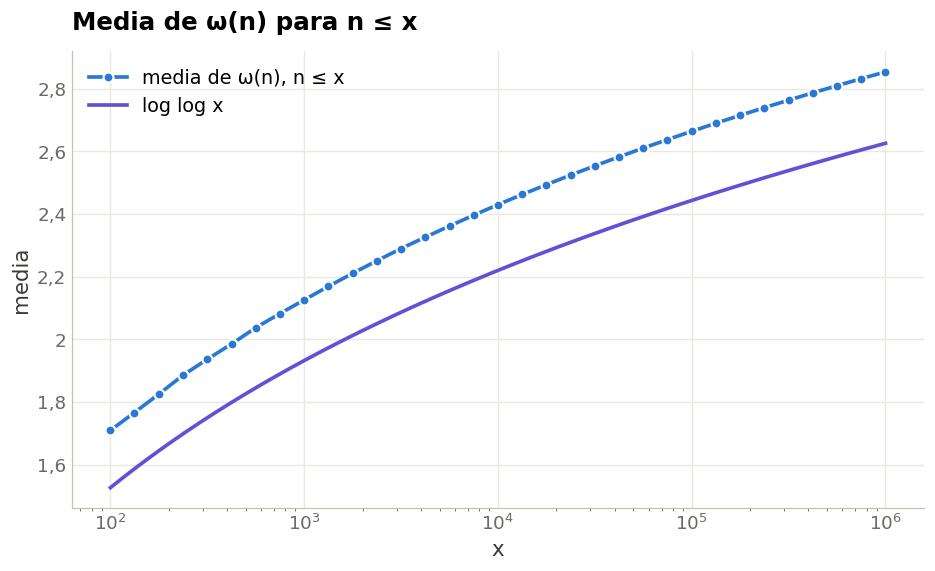

In [ ]:
xx = np.logspace(2, math.log10(N), 2000)

fig, ax = plt.subplots()
puntos(ax, xs, media, AZUL, 'media de ω(n), n ≤ x')

#ax.plot(xx, np.sin(xx), color=GRIS, lw=1.2, label='sen x')
#ax.plot(xx, xx, color=NARANJA, label='x')
#ax.plot(xx, np.log(xx), color=VERDE, label='log x')
ax.plot(xx, np.log(np.log(xx)), color=VIOLETA, label='log log x')

ax.set(xscale='log', xlabel='x', ylabel='media', title='Media de ω(n) para n ≤ x')
ax.yaxis.set_major_formatter(coma_fmt)
ax.legend(loc='upper left')
plt.show()

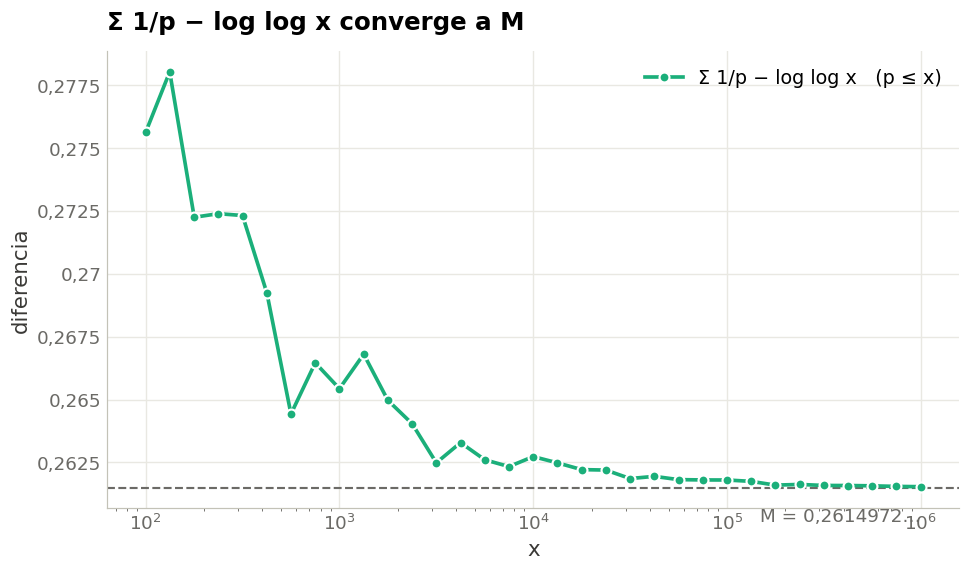

x = 10⁶:   Σ1/p − log log x = 0,261536


In [ ]:

lim = np.searchsorted(primos, xs, side='right')
S1, S2 = np.empty(len(xs)), np.empty(len(xs))
s1 = s2 = 0.0; a = 0
for i, b in enumerate(lim):
    q = 1.0 / primos[a:b]
    s1 += q.sum(); s2 += (q * q).sum()
    S1[i], S2[i], a = s1, s2, b

fig, ax = plt.subplots()
ax.axhline(M, color=GRIS, lw=1.4, ls='--', zorder=2)
ax.text(xs[-1], M - 0.0008, f'M = {coma(M, 7)}…', color=GRIS, fontsize=12, va='top', ha='right')
puntos(ax, xs, S1 - lam, VERDE, 'Σ 1/p − log log x   (p ≤ x)')
ax.set(xscale='log', xlabel='x', ylabel='diferencia', title='Σ 1/p − log log x converge a M')
ax.yaxis.set_major_formatter(coma_fmt)
ax.legend(loc='upper right')
plt.show()

print(f'x = {pot10(N)}:   Σ1/p − log log x = {coma(S1[-1] - lam[-1], 6)}')

**Segundo teorema de Mertens (1874).**

$$
\sum_{p\le x}\frac{1}{p}=\log\log x+M+O\!\left(\frac{1}{\log x}\right),\qquad M=0{,}2614972\ldots
$$

$$
\frac{1}{x}\sum_{n\le x}\omega(n)=\sum_{p\le x}\frac{1}{x}\left\lfloor\frac{x}{p}\right\rfloor=\log\log x+M+o(1)
$$

## 4. ¿Cómo se distribuye ω(n)?

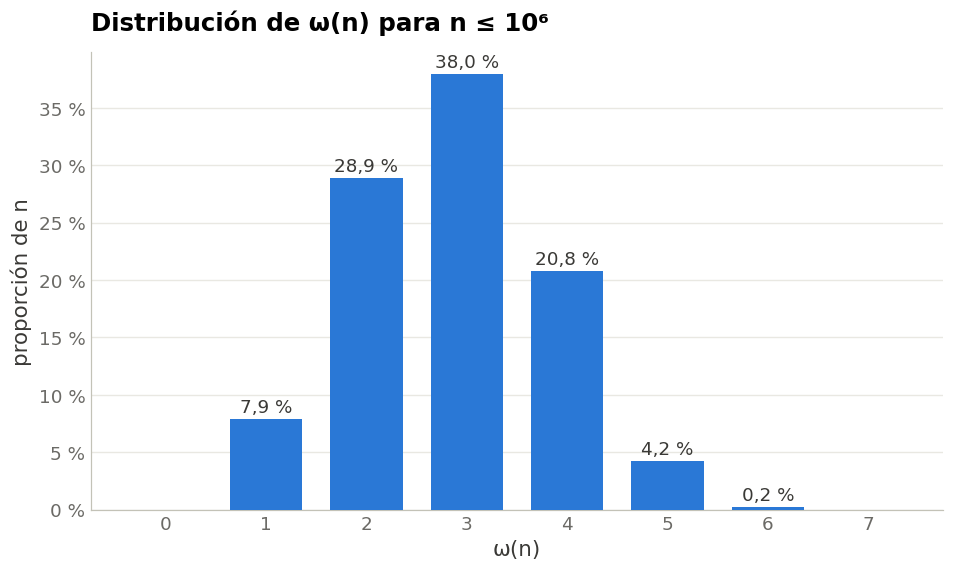

In [ ]:
p_N = pmf[-1]
fig, ax = plt.subplots()
ax.bar(k, p_N, width=0.72, color=AZUL, zorder=3)
for kk, v in zip(k, p_N):
    if v >= 0.001:
        ax.text(kk, v + 0.006, coma(100 * v, 1) + ' %', ha='center', fontsize=12, color='#3a3936')

mu, s = media[-1], math.sqrt(varianza[-1])
# zz = np.linspace(-0.5, K - 0.5, 400)
# ax.plot(zz, np.exp(-(zz - mu)**2 / (2 * s * s)) / math.sqrt(2 * math.pi * s * s), color=NARANJA, zorder=4,
#         label=f'normal: media {coma(mu, 2)}, varianza {coma(s * s, 2)}')
# ax.legend(loc='upper right')

ax.set(xticks=k, xlabel='ω(n)', ylabel='proporción de n', title=f'Distribución de ω(n) para n ≤ {pot10(N)}')
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{100 * v:.0f} %'))
ax.grid(axis='x', visible=False)
plt.show()

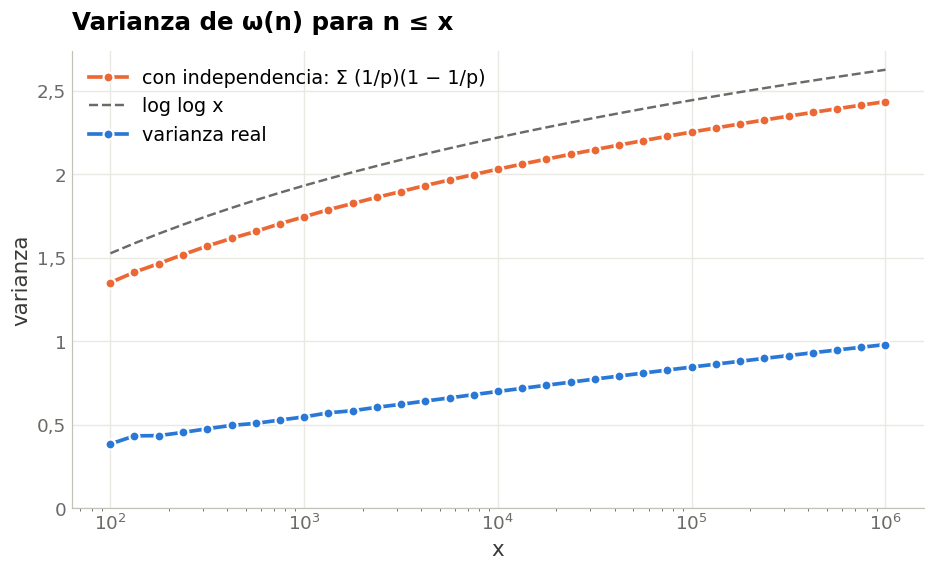

x = 10⁶:   real 0,981    independencia 2,435    log log x 2,626
real − log log x = -1,645


In [ ]:
fig, ax = plt.subplots()
puntos(ax, xs, S1 - S2, NARANJA, 'con independencia: Σ (1/p)(1 − 1/p)')
ax.plot(xs, lam, color=GRIS, ls='--', lw=1.6, label='log log x')
puntos(ax, xs, varianza, AZUL, 'varianza real')
ax.set(xscale='log', xlabel='x', ylabel='varianza', ylim=(0, None),
       title='Varianza de ω(n) para n ≤ x')
ax.yaxis.set_major_formatter(coma_fmt)
ax.legend(loc='upper left')
plt.show()

print(f'x = {pot10(N)}:   real {coma(varianza[-1])}    independencia {coma(S1[-1] - S2[-1])}    log log x {coma(lam[-1])}')
print(f'real − log log x = {coma(varianza[-1] - lam[-1])}')

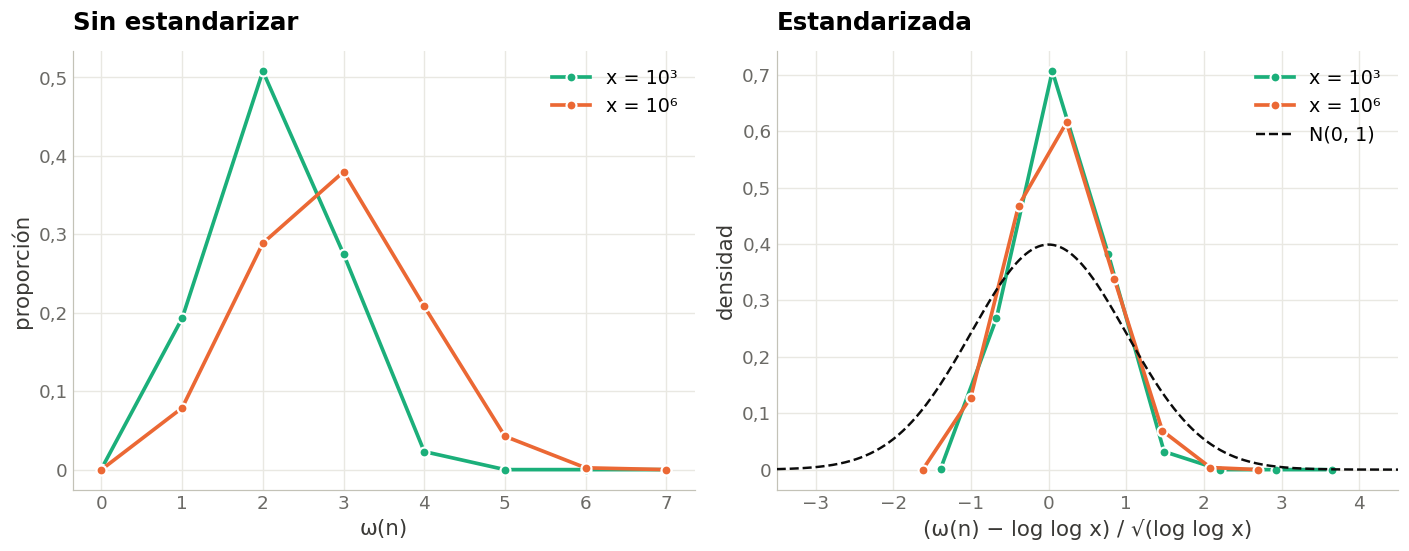

In [ ]:

elegidos = [i for i, x in enumerate(xs) if x in (10**3, 10**6, N)]
colores = [VERDE, NARANJA, AZUL]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))
for i, c in zip(elegidos, colores):
    puntos(ax1, k, pmf[i], c, f'x = {pot10(xs[i])}')
    z = (k - lam[i]) / math.sqrt(lam[i])
    puntos(ax2, z, pmf[i] * math.sqrt(lam[i]), c, f'x = {pot10(xs[i])}')
zz = np.linspace(-3.5, 4.5, 400)
ax2.plot(zz, np.exp(-zz**2 / 2) / math.sqrt(2 * math.pi), color='#0b0b0b', lw=1.6, ls='--', label='N(0, 1)', zorder=4)
ax1.set(xticks=k, xlabel='ω(n)', ylabel='proporción', title='Sin estandarizar')
ax2.set(xlabel='(ω(n) − log log x) / √(log log x)', ylabel='densidad', title='Estandarizada', xlim=(-3.5, 4.5))
for a_ in (ax1, ax2):
    a_.yaxis.set_major_formatter(coma_fmt); a_.legend(loc='upper right')
plt.tight_layout()
plt.show()

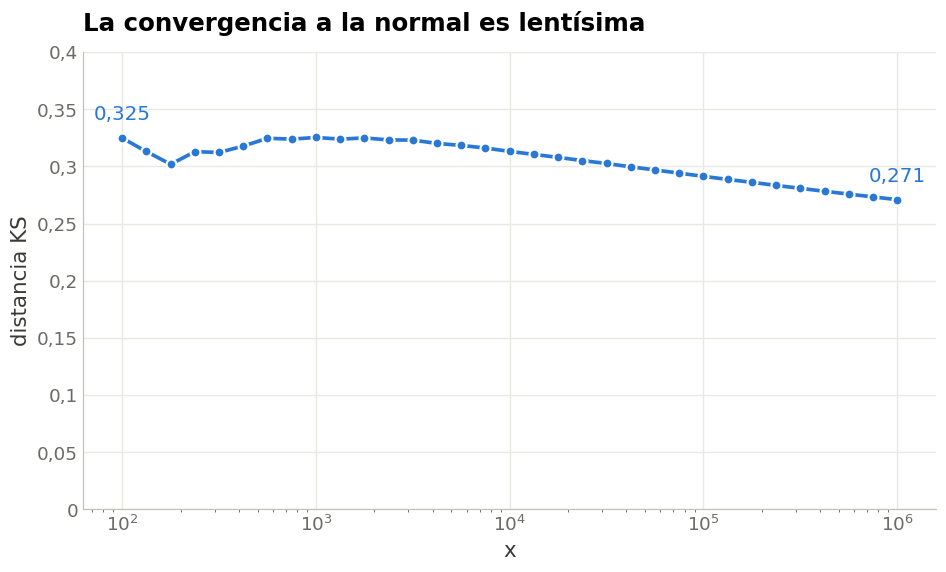

In [ ]:
Phi = np.vectorize(lambda z: 0.5 * (1 + math.erf(z / math.sqrt(2))))
D = np.empty(len(xs))
for i in range(len(xs)):
    z = (k - lam[i]) / math.sqrt(lam[i])
    F = np.cumsum(pmf[i]); F_antes = F - pmf[i]
    D[i] = max(np.abs(F - Phi(z)).max(), np.abs(F_antes - Phi(z)).max())

fig, ax = plt.subplots()
puntos(ax, xs, D, AZUL, 'distancia a N(0, 1)')
ax.set(xscale='log', xlabel='x', ylabel='distancia KS', ylim=(0, 0.4),
       title='La convergencia a la normal es lentísima')
ax.yaxis.set_major_formatter(coma_fmt)
for i in (0, len(xs) - 1):
    ax.annotate(coma(D[i], 3), (xs[i], D[i]), textcoords='offset points', xytext=(0, 12), ha='center', color=AZUL)
plt.show()

**Aproximación (eventos $p\mid n$ independientes).** Si cada $[\,p\mid n\,]$ fuera una variable de Bernoulli independiente de parámetro $1/p$, por el teorema central del límite

$$
\omega(n)=\sum_{p\le x}[\,p\mid n\,]\;\approx\;N\big(\log\log x,\ \log\log x\big)
\qquad\Longleftrightarrow\qquad
\frac{\omega(n)-\log\log x}{\sqrt{\log\log x}}\;\approx\;N(0,1)
$$

**Teorema de Erdős–Kac (1940).** Para todo $a<b$ fijos,

$$
\lim_{x\to\infty}\frac{1}{x}\,\#\left\{n\le x:\ a\le\frac{\omega(n)-\log\log n}{\sqrt{\log\log n}}\le b\right\}=\frac{1}{\sqrt{2\pi}}\int_a^b e^{-t^2/2}\,dt
$$

## 5. ¿Esto pa' qué sirve?

In [ ]:

def es_primo(n):
    """Miller–Rabin con bases fijas: exacto para n < 3,3·10²⁴."""
    if n < 2:
        return False
    for p in (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37):
        if n % p == 0:
            return n == p
    d, s = n - 1, 0
    while d % 2 == 0:
        d //= 2; s += 1
    for a in (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37):
        x = pow(a, d, n)
        if x in (1, n - 1):
            continue
        for _ in range(s - 1):
            x = x * x % n
            if x == n - 1:
                break
        else:
            return False
    return True

def un_factor(n):
    """Pollard rho con la variante de Brent: devuelve un factor no trivial de n compuesto."""
    if n % 2 == 0:
        return 2
    while True:
        y, c, m = random.randrange(1, n), random.randrange(1, n), 128
        g = r = q = 1
        while g == 1:
            x = y
            for _ in range(r):
                y = (y * y + c) % n
            j = 0
            while j < r and g == 1:
                ys = y
                for _ in range(min(m, r - j)):
                    y = (y * y + c) % n
                    q = q * abs(x - y) % n
                g = math.gcd(q, n); j += m
            r *= 2
        if g == n:
            g = 1
            while g == 1:
                ys = (ys * ys + c) % n
                g = math.gcd(abs(x - ys), n)
        if g != n:
            return g

def primos_distintos(n):
    ps = set()
    for p in (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47):
        while n % p == 0:
            ps.add(p); n //= p
    pila = [n] if n > 1 else []
    while pila:
        m = pila.pop()
        if m == 1:
            continue
        if es_primo(m):
            ps.add(m)
        else:
            d = un_factor(m); pila += [d, m // d]
    return ps

CUANTOS = 1391
random.seed(2026)
t = time.perf_counter()
w64 = np.array([len(primos_distintos(random.randrange(2**63, 2**64))) for _ in range(CUANTOS)])
print(f'{CUANTOS} enteros aleatorios de 64 bits factorizados en {coma(time.perf_counter() - t, 1)} s')

1391 enteros aleatorios de 64 bits factorizados en 1,9 s


log log 2⁶⁴ = 3,792

                         teorema   corregida   observada
media                      3,792       4,054       4,057
varianza                   3,792       2,148       2,065


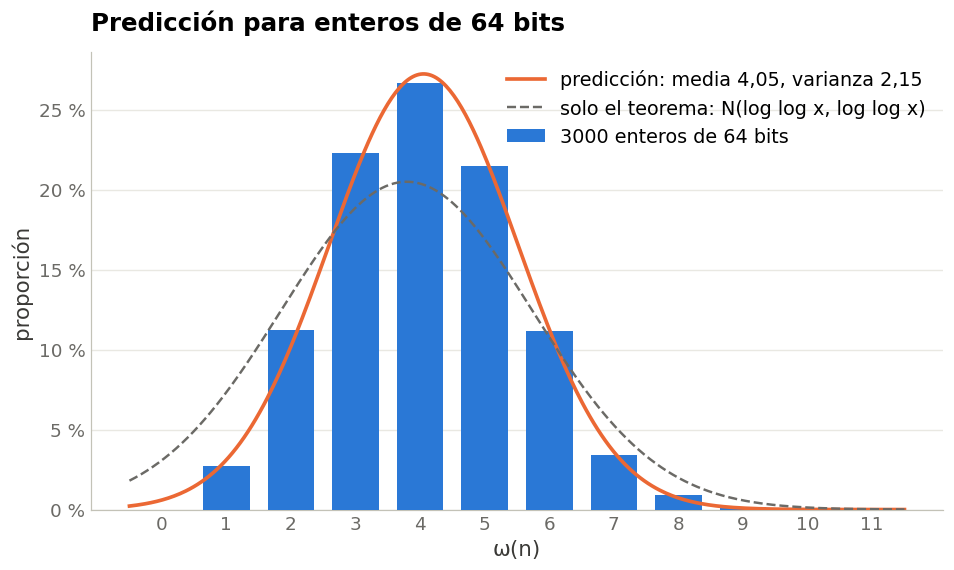

In [ ]:
L = math.log(math.log(2**64))                      # log log 2⁶⁴
c_var = varianza[-1] - lam[-1]                     # corrección de la varianza medida con la criba
pred_media, pred_var = L + M, L + c_var

print(f'log log 2⁶⁴ = {coma(L)}\n')
print(f'{"":22}{"teorema":>10}{"corregida":>12}{"observada":>12}')
print(f'{"media":22}{coma(L):>10}{coma(pred_media):>12}{coma(w64.mean()):>12}')
print(f'{"varianza":22}{coma(L):>10}{coma(pred_var):>12}{coma(w64.var()):>12}')

K64 = 12
k64 = np.arange(K64)
frec = np.bincount(w64, minlength=K64)[:K64] / len(w64)
zz = np.linspace(-0.5, K64 - 0.5, 400)
normal = lambda mu, v: np.exp(-(zz - mu)**2 / (2 * v)) / math.sqrt(2 * math.pi * v)

fig, ax = plt.subplots()
ax.bar(k64, frec, width=0.72, color=AZUL, zorder=3, label=f'{CUANTOS} enteros de 64 bits')
ax.plot(zz, normal(pred_media, pred_var), color=NARANJA, zorder=4,
        label=f'predicción: media {coma(pred_media, 2)}, varianza {coma(pred_var, 2)}')
ax.plot(zz, normal(L, L), color=GRIS, ls='--', lw=1.6, zorder=4, label='solo el teorema: N(log log x, log log x)')
ax.set(xticks=k64, xlabel='ω(n)', ylabel='proporción', title='Predicción para enteros de 64 bits')
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{100 * v:.0f} %'))
ax.grid(axis='x', visible=False)
ax.legend(loc='upper right')
plt.show()

# ¡Gracias!

**Referencias**

- P. Erdős y M. Kac, *The Gaussian Law of Errors in the Theory of Additive Number Theoretic Functions*, American Journal of Mathematics 62 (1940), 738–742.
- G. H. Hardy y S. Ramanujan, *The normal number of prime factors of a number n*, Quarterly Journal of Mathematics 48 (1917), 76–92.
- A. Rényi y P. Turán, *On a theorem of Erdős–Kac*, Acta Arithmetica 4 (1958), 71–84.